## porespy + phbin


In [1]:
import porespy as ps
import matplotlib.pyplot as plt
import numpy as np
import phbin, cv2
import scipy
import scipy.stats as spst
from IPython.display import display, Image
import random

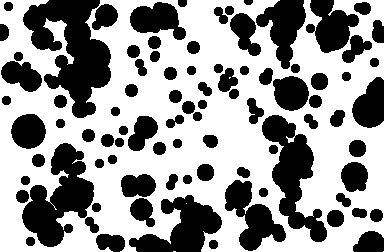

In [2]:
shape=[252,384]
porosity = 0.6
dist = spst.norm(loc=10,scale=5)
sem0 = ps.generators.polydisperse_spheres(shape,porosity,dist,nbins=4)
plt.imsave('./input.png',sem0,cmap='gray')
display(Image('./input.png'))

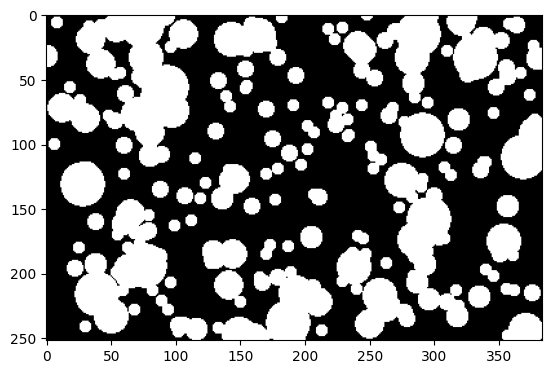

In [3]:
img, input_bin = phbin.make_input_imgobj('./input.png',th=150)
plt.close()
plt.imshow(input_bin,cmap='gray')

## persistent homology

In [4]:
pds = phbin.make_pd([input_bin],mode='sublevel',dim=0)

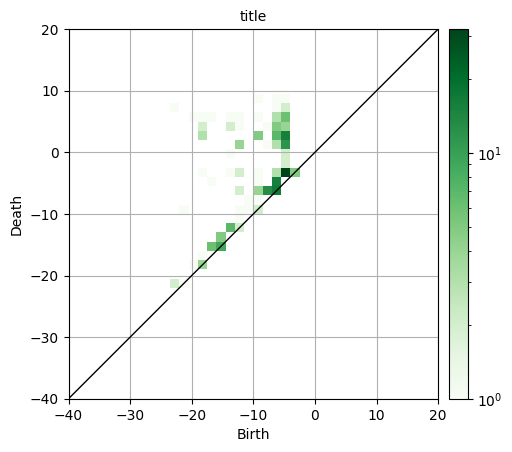

In [5]:
phbin.draw_pd_color(pds[0],x_range=[-40,20],x_bins=40, cmap='Greens')

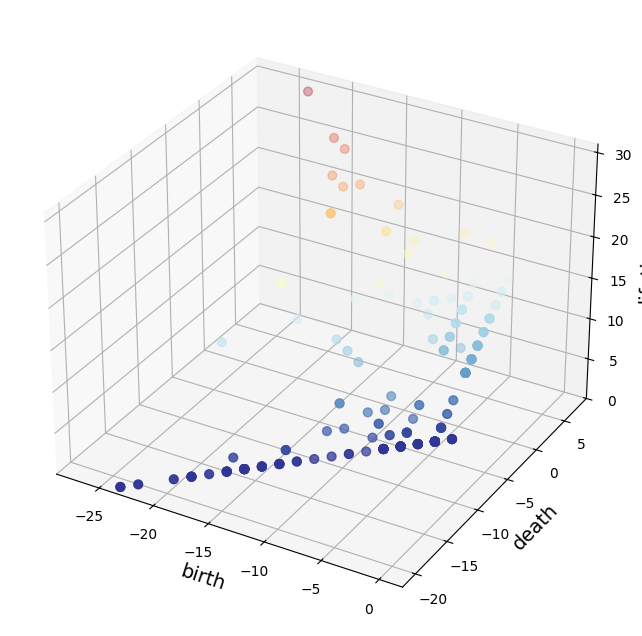

<Figure size 640x480 with 0 Axes>

In [6]:
phbin.draw_pd_lifetime(pds[0])

In [7]:
piimage = phbin.make_pi(pds,mesh_range=(-30,10),bins=35,sigma=1.0,weight=('atan',0.0001,15),superlevel=False)

In [8]:
pi = np.array(piimage['pi'][0])
mesh = piimage['mesh']

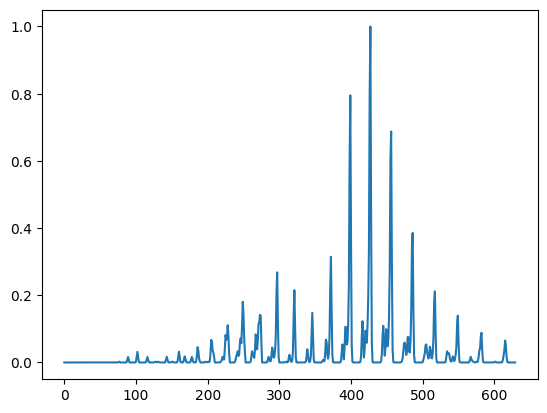

In [9]:
plt.close()
plt.plot(pi)

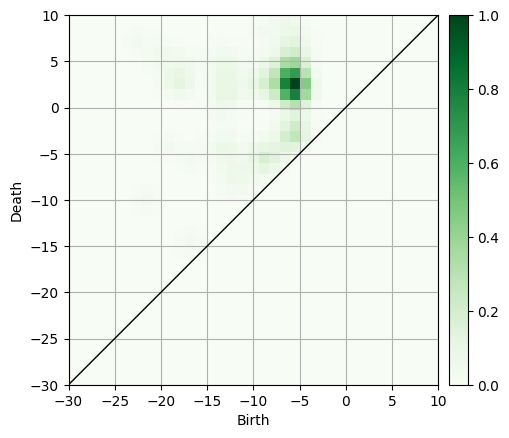

In [10]:
phbin.draw_pi_color(pi,mesh,cmap='Greens')

## Reverse Map

In [12]:
phtrees = phbin.make_phtrees([input_bin],mode='sublevel',dim=0)

In [13]:
area = mesh.mask_from_vector(pi>0.2)

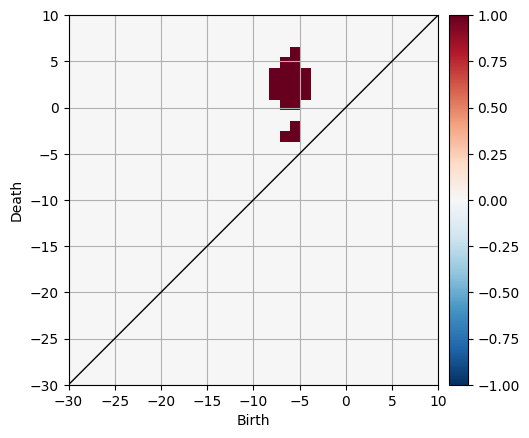

In [14]:
area.plot(colorbar={"type":"linear-midpoint","midpoint":0.0})

In [15]:
nodes = phbin.pd_filter(pds[0],phtrees[0],area)

In [16]:
phbin.reverse_map(nodes,img)

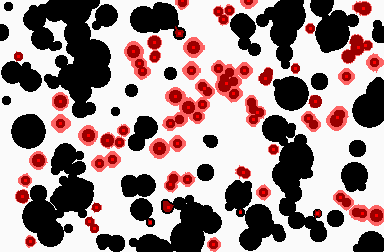

In [17]:
display(Image('./reverse.png'))